In [19]:
import os
from pathlib import Path
import sys

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch

from src.data import get_eval_transforms
from src.gate import IMAGE_EXTS, GateEvaluationResult, SmartGate
from src.models import FaceEmbeddingNet

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)

# Point these to your trained model weights and image folders
CHECKPOINT_PATH = Path("notebooks/checkpoints/resnet18_triplet/best_model.pt")
GALLERY_DIR = Path("data/faces/test/gate_gallery")
PROBES_DIR = Path("data/faces/test/gate_probes")

model = FaceEmbeddingNet(
    backbone="resnet18",
    embedding_dim=128,
    pretrained=False,
)
ckpt = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])

gate = SmartGate(
    model=model,
    threshold=0.5,
    transform=get_eval_transforms((128, 128)),
    device=device,
)

# Enroll directly from the folder of images
num_enrolled = gate.enroll_gallery(GALLERY_DIR)
print(f"Enrolled {num_enrolled} identities directly from {GALLERY_DIR}")
print(f"Sample identities: {gate.gallery_identities[:5]}")

Enrolled 32 identities directly from data/faces/test/gate_gallery
Sample identities: ['Alastair_Campbell', 'Ana_Guevara', 'Ann_Veneman', 'Anna_Kournikova', 'Antonio_Palocci']


In [28]:
thresholds = np.linspace(0.05, 1.60, num=60)
sweep_results = gate.sweep_thresholds(PROBES_DIR, thresholds=thresholds, batch_size=64)

best_bal = max(sweep_results, key=lambda r: r.balanced_accuracy)
far5_candidates = [r for r in sweep_results if r.far <= 0.05]
best_far5 = max(far5_candidates, key=lambda r: r.tar) if far5_candidates else best_bal


def _print_row(label: str, res: GateEvaluationResult) -> None:
    print(
        f"{label:<24} | tau={res.threshold:.3f} | "
        f"TAR={res.tar:6.1%} | FAR={res.far:6.1%} | FRR={res.frr:6.1%} | "
        f"BalAcc={res.balanced_accuracy:6.1%}"
    )


_print_row("Max Balanced Accuracy", best_bal)
_print_row("High Security (FAR<=5%)", best_far5)

# Set calibrated threshold on the in-memory gate instance
gate.threshold = best_bal.threshold
print(f"\nActive threshold set to tau = {gate.threshold:.3f}")

Max Balanced Accuracy    | tau=1.101 | TAR= 58.2% | FAR= 40.7% | FRR= 41.8% | BalAcc= 58.7%
High Security (FAR<=5%)  | tau=0.786 | TAR= 12.4% | FAR=  5.0% | FRR= 87.6% | BalAcc= 53.7%

Active threshold set to tau = 1.101


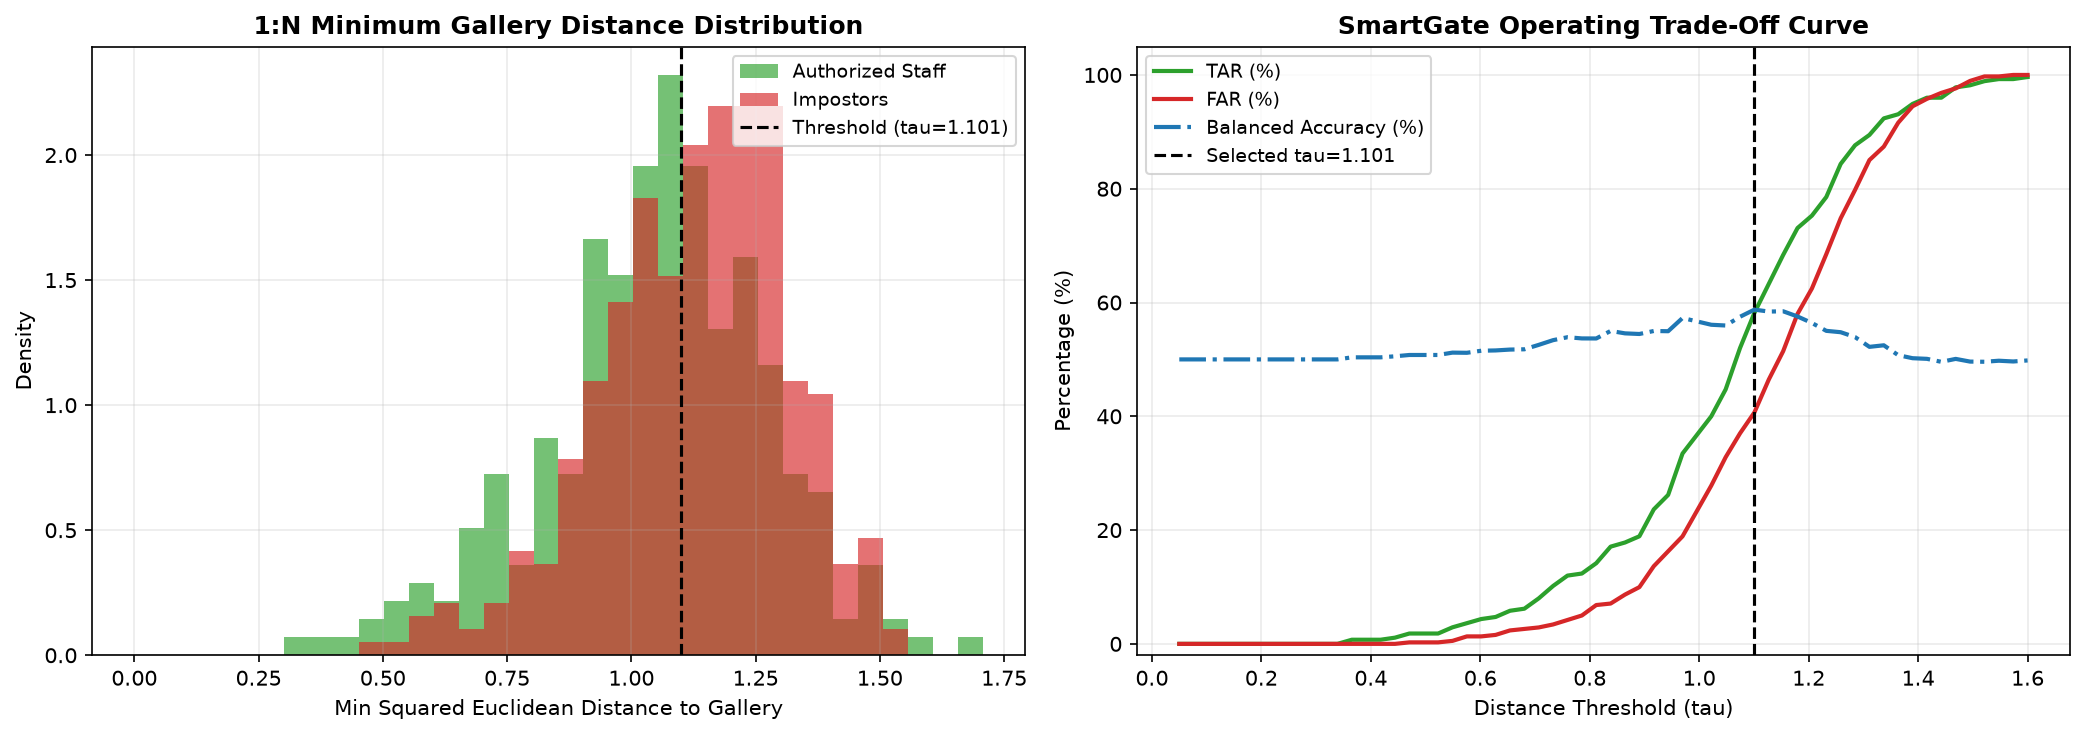

In [29]:
auth_dists, imp_dists = gate.extract_probe_distances(PROBES_DIR, batch_size=64)

taus = [r.threshold for r in sweep_results]
tars = [r.tar * 100 for r in sweep_results]
fars = [r.far * 100 for r in sweep_results]
bal_accs = [r.balanced_accuracy * 100 for r in sweep_results]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

ax1 = axes[0]
bins = np.linspace(0.0, max(float(auth_dists.max()), float(imp_dists.max())) + 0.05, 35)
ax1.hist(auth_dists, bins=bins, alpha=0.65, density=True, color="tab:green", label="Authorized Staff")
ax1.hist(imp_dists, bins=bins, alpha=0.65, density=True, color="tab:red", label="Impostors")
ax1.axvline(gate.threshold, color="black", linestyle="--", linewidth=1.5, label=f"Threshold (tau={gate.threshold:.3f})")
ax1.set_title("1:N Minimum Gallery Distance Distribution", fontsize=12, fontweight="bold")
ax1.set_xlabel("Min Squared Euclidean Distance to Gallery")
ax1.set_ylabel("Density")
ax1.legend(loc="upper right", fontsize=9)
ax1.grid(True, alpha=0.25)

ax2 = axes[1]
ax2.plot(taus, tars, color="tab:green", linewidth=2, label="TAR (%)")
ax2.plot(taus, fars, color="tab:red", linewidth=2, label="FAR (%)")
ax2.plot(taus, bal_accs, color="tab:blue", linestyle="-.", linewidth=2, label="Balanced Accuracy (%)")
ax2.axvline(gate.threshold, color="black", linestyle="--", linewidth=1.5, label=f"Selected tau={gate.threshold:.3f}")
ax2.set_title("SmartGate Operating Trade-Off Curve", fontsize=12, fontweight="bold")
ax2.set_xlabel("Distance Threshold (tau)")
ax2.set_ylabel("Percentage (%)")
ax2.set_ylim(-2, 105)
ax2.legend(loc="best", fontsize=9)
ax2.grid(True, alpha=0.25)

plt.tight_layout()
fig_dir = Path("reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "smartgate_threshold_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

In [31]:
def test_gate_with_photo(
    gate_system: SmartGate,
    probe_path: str | Path,
    gallery_dir: str | Path = GALLERY_DIR,
) -> None:
    probe_file = Path(probe_path)
    decision = gate_system.verify(probe_file)

    fig, axes = plt.subplots(1, 2, figsize=(7, 3.8), dpi=130)

    with Image.open(probe_file) as img:
        axes[0].imshow(img.convert("RGB"))
    axes[0].set_title(f"Probe: {probe_file.parent.name}\n({probe_file.name})", fontsize=10)
    axes[0].axis("off")

    if decision.access_granted and decision.matched_identity is not None:
        ref_files = sorted(
            p
            for p in Path(gallery_dir).rglob(f"*{decision.matched_identity}*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS
        )
        if ref_files:
            with Image.open(ref_files[0]) as ref_img:
                axes[1].imshow(ref_img.convert("RGB"))
        axes[1].set_title(
            f"ACCESS GRANTED\nMatched: {decision.matched_identity}",
            fontsize=10,
            color="green",
            fontweight="bold",
        )
    else:
        axes[1].text(
            0.5,
            0.5,
            "ACCESS DENIED\n(No Match Below Threshold)",
            ha="center",
            va="center",
            fontsize=11,
            color="crimson",
            fontweight="bold",
        )
        axes[1].set_facecolor("#f8f8f8")
        axes[1].set_xticks([])
        axes[1].set_yticks([])

    axes[1].axis("off")
    fig.suptitle(
        f"Dist = {decision.min_distance:.3f} (tau = {decision.threshold:.3f}) | "
        f"Cosine Sim = {decision.similarity_score:.3f}",
        fontsize=11,
        fontweight="bold",
    )
    plt.tight_layout()
    plt.show()


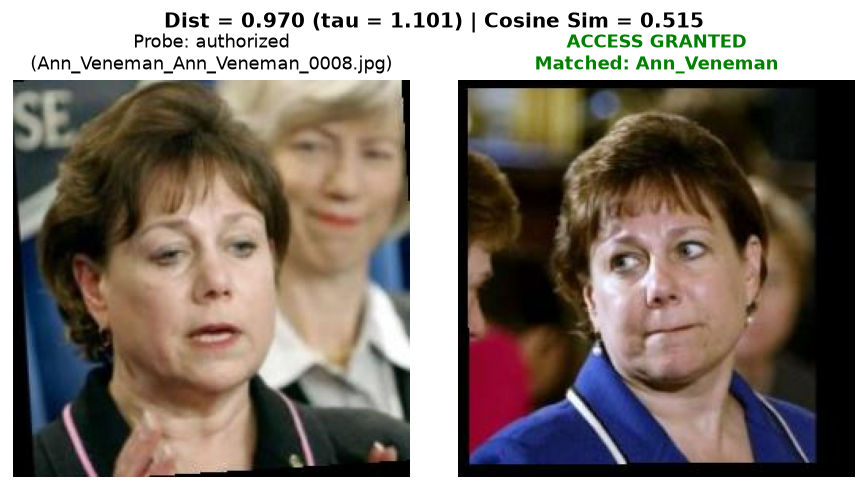

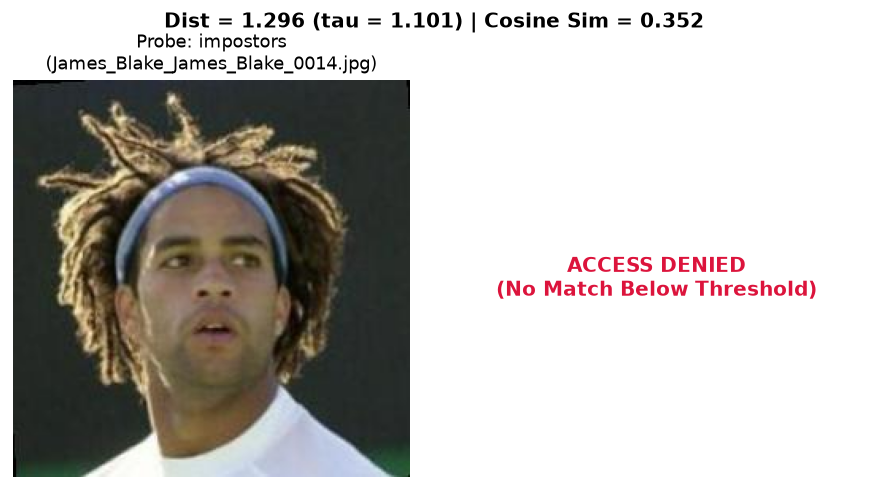

In [43]:
import random


auth_persons =[
    p for p in sorted((PROBES_DIR / "authorized").rglob("*"))
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]
imposters = [
    p for p in sorted((PROBES_DIR / "impostors").rglob("*"))
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]

sample_auth = random.sample(auth_persons, 1)[0]
sample_imp = random.sample(imposters, 1)[0]

test_gate_with_photo(gate, sample_auth)
test_gate_with_photo(gate, sample_imp)